#Pi estimates with a probability approach


#0. Imports and Useful functions

NumPy and Matplotlib are used for numerical analysis and visualization, while the Random module is used to generate the random samples required by the Monte Carlo methods. SciPy's `quad` function is used to numerically evaluate the theoretical means, variances and covariances used as benchmarks.

With its default settings, `quad` uses an absolute tolerance and a relative tolerance of approximately $1.49\times10^{-8}$. The integration algorithm aims to make its estimated absolute error satisfy

$$
|I-\hat I|
\lesssim
\max\left(1.49\times10^{-8},\,
1.49\times10^{-8}|I|\right).
$$

These values represent numerical error tolerances used by the integration algorithm, rather than a rigorous guarantee on the true integration error.

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import random as rd
import math
import time
from scipy.integrate import quad




In [5]:
seed = 42

rd.seed(seed)
np.random.seed(seed)

In [6]:
def confidence_interval(func, M, r):
  return r*math.sqrt(approx_variance(func))/math.sqrt(M)

def approx_mean(func):
  return quad(func, 0, 1)[0]

def approx_variance(func):
  E_func_squared = quad(lambda x: func(x)**2, 0, 1)[0]
  mean_func_squared = (approx_mean(func))**2
  return E_func_squared - mean_func_squared

def approx_covariance(func1, func2):
  return quad(lambda x: func1(x)*func2(x), 0, 1)[0] - approx_mean(func1)*approx_mean(func2)

f = lambda x: 1/(2*math.sqrt((1-(x/2)**2)))

r = 1.96



#1. Theoretical estimations and Standard MC method


Let $U_1,\ldots,U_M$ be independent random variables uniformly distributed on $[0,1]$. Since

$$
I=\mathbb{E}[f(U)],
$$

the standard Monte Carlo estimator is

$$
\hat I_M=\frac{1}{M}\sum_{i=1}^{M}f(U_i).
$$
All the methods considered below aim to approximate

$$
I=\int_0^1 \frac{1}{2\sqrt{1-(x/2)^2}}\,dx=\frac{\pi}{6}.
$$

Therefore, an estimator $\hat I$ of the integral provides the estimator

$$
\hat\pi = 6\hat I.
$$

Consequently, bias, RMSE and margin of error must be multiplied by 6 when expressed in terms of $\pi$, while variances must be multiplied by $36$.





## Monte Carlo method


In [7]:
def MonteCarlo_Simulation(f, iter):        #f is the function, a and b are the lower and upper bound for the interval, iter is the number of the realizations done by the random vector X of the inputs
  sum = 0
  for i in range(iter):
    x = rd.uniform(0, 1)
    sum += f(x)
  approx_value = sum/iter
  return approx_value




Series of experiments


NUMBER OF ITERATIONS = 100 
time spent: 0.014882802963256836 
empirical bias: -3.417147954964395e-05 
empirical variance: 5.320944676598897e-06 
sample variance: 5.3746915925241384e-06 
RMSE: 0.0023069703870257 
margin of error: 0.0043712585939228625 
empirical coverage probability: 93 % 

NUMBER OF ITERATIONS = 1000 
time spent: 0.11339187622070312 
empirical bias: 8.477320472576323e-06 
empirical variance: 4.778432656807021e-07 
sample variance: 4.826699653340425e-07 
RMSE: 0.0006913140607879293 
margin of error: 0.001382313339838131 
empirical coverage probability: 96 % 

NUMBER OF ITERATIONS = 10000 
time spent: 1.8099730014801025 
empirical bias: -1.2344424323320613e-05 
empirical variance: 5.312912442309526e-08 
sample variance: 5.3665782245550764e-08 
RMSE: 0.0002308278779414858 
margin of error: 0.00043712585939228624 
empirical coverage probability: 93 % 

NUMBER OF ITERATIONS = 100000 
time spent: 5.753344774246216 
empirical bias: -1.1956368662670025e-05 
empirical variance:

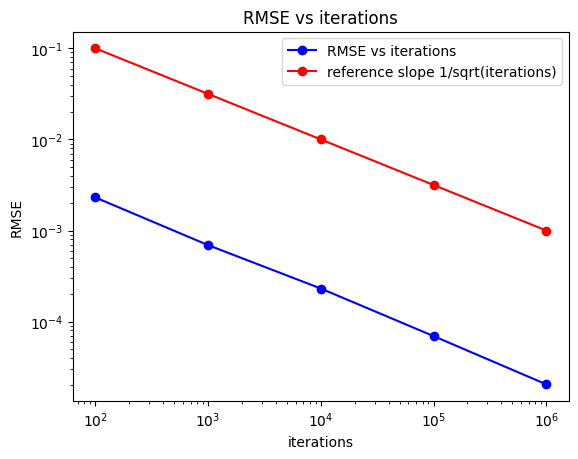

In [8]:
RMSEs = np.zeros(5)
iters = np.zeros(5)
for i in range(2, 7):
  iter = 10**i
  iters[i-2] = iter
  approx_values = np.zeros(100)
  start = time.time()
  for j in range(100):
    approx_value = MonteCarlo_Simulation(f, iter)
    approx_values[j] = approx_value
  end = time.time()

  empirical_bias = (1/100)*(np.sum(approx_values - math.pi/6))

  mean_of_approx = np.mean(approx_values)
  sample_var = (1/99)*(np.sum((approx_values - mean_of_approx)**2))

  empirical_var = sample_var * 99/100

  RMSE = np.sqrt((1/100)*(np.sum((approx_values - math.pi/6)**2)))
  RMSEs[i-2] = RMSE

  conf_int = confidence_interval(f, iter, r)

  num = 0
  for j in range(100):
    if math.pi/6 - conf_int < approx_values[j] < math.pi/6 + conf_int:
      num += 1

  print(f"NUMBER OF ITERATIONS = {iter} \n"
  f"time spent: {end - start} \n"
  f"empirical bias: {empirical_bias} \n"
  f"empirical variance: {empirical_var} \n"
  f"sample variance: {sample_var} \n"
  f"RMSE: {RMSE} \n"
  f"margin of error: {conf_int} \n"
  f"empirical coverage probability: {num} % \n"
  )

plt.loglog(iters, RMSEs, 'b-o', label = 'RMSE vs iterations')
g = lambda x: 1/math.sqrt(x)
sqrt_values = np.zeros(len(iters))
for i in range(len(iters)):
  sqrt_values[i] = g(iters[i])
plt.loglog(iters, sqrt_values, 'r-o', label = 'reference slope 1/sqrt(iterations)')
plt.title('RMSE vs iterations')
plt.xlabel('iterations')
plt.ylabel('RMSE')
plt.legend()
plt.show()




Using Chebyshev's inequality, for a given error tolerance $\epsilon$ and probability threshold $p$, we can estimate the number of iterations required to guarantee

$$
P(|\hat I_M-I|\geq\epsilon)\leq p.
$$

Since

$$
P(|\hat I_M-I|\geq\epsilon)
\leq
\frac{\operatorname{Var}(f(U))}{M\epsilon^2},
$$

it is sufficient to choose

$$
M\geq\frac{\operatorname{Var}(f(U))}{p\epsilon^2}.
$$

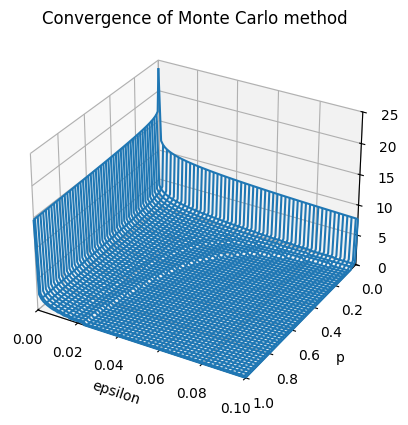

In [9]:
epsilons = np.linspace(1e-9, 0.1, 100)
p = np.linspace(1e-9, 1, 100)


x = approx_variance(f)


iterations = np.zeros((100, 100))
for i in range(100):
  for j in range(100):                                                                           #number of needed iterations to obtain that the probability of the error being greater than epsilon[i] is less than p[i]
    iterations[i][j] = math.ceil(abs(x/(p[i]*epsilons[j]**2)))


fig, ax = plt.subplots(subplot_kw={"projection": "3d"})


x = epsilons
y = p
X, Y = np.meshgrid(x, y)
Z = np.log10(iterations)                                                                          #number of iterations in log10

ax.plot_wireframe(X, Y, Z, color='C0')
ax.set(xlim=(0, 0.1), ylim=(1, 0), zlim=(0, 25))


plt.title('Convergence of Monte Carlo method')
ax.set_xlabel('epsilon')
ax.set_ylabel('p')
plt.show()

#2. Antithetic Sampling

This method aims to reduce the variance of the estimator by pairing each sample $U_i$ with its antithetic counterpart $1-U_i$:

$$
\hat I_M^{AV}
=
\frac{1}{M}
\sum_{i=1}^{M}
\frac{f(U_i)+f(1-U_i)}{2}.
$$

When $f(U)$ and $f(1-U)$ are negatively correlated, the variance of their average is smaller than the variance of the standard Monte Carlo estimator.

Since each antithetic pair requires two evaluations of $f$, the number of pairs is halved when comparing the methods at the same number of function evaluations.

In [10]:


def Monte_Carlo_antithetic_sampl(f, iter):
  sum = 0
  for i in range(iter):
    x = rd.uniform(0, 1)
    sum += (f(x) + f(1-x))/2
  approx_value = sum/iter
  return approx_value


def improvement_measure_ant_sampl(f):
  g = lambda x: f(1-x)
  return 1/2 + 1/2*approx_covariance(f, g)/approx_variance(f)


imp_meas_ant_sampl = improvement_measure_ant_sampl(f)
print(f'The theoretical improvement of the variance is {(1/imp_meas_ant_sampl)/2}')

The theoretical improvement of the variance is 5.7660072363387


Series of experiments

NUMBER OF FUNCTION EVALUATIONS = 100 
NUMBER OF ANTITHETIC PAIRS = 50 
time spent: 0.014020204544067383 
empirical bias: -8.527098513244846e-05 
empirical variance: 6.168546790772345e-07 
sample variance: 6.23085534421449e-07 
RMSE: 0.0007900163415921805 
margin of error: 0.0018204087218031892 
empirical coverage probability: 100 % 

NUMBER OF FUNCTION EVALUATIONS = 1000 
NUMBER OF ANTITHETIC PAIRS = 500 
time spent: 0.053899288177490234 
empirical bias: 3.870935084164584e-05 
empirical variance: 8.904978837937508e-08 
sample variance: 8.994928119128796e-08 
RMSE: 0.00030091228326865736 
margin of error: 0.0005756637833333899 
empirical coverage probability: 94 % 

NUMBER OF FUNCTION EVALUATIONS = 10000 
NUMBER OF ANTITHETIC PAIRS = 5000 
time spent: 0.46460652351379395 
empirical bias: -1.29526841102523e-05 
empirical variance: 8.073464006863233e-09 
sample variance: 8.155014148346699e-09 
RMSE: 9.078125375055807e-05 
margin of error: 0.00018204087218031892 
empirical coverage probabi

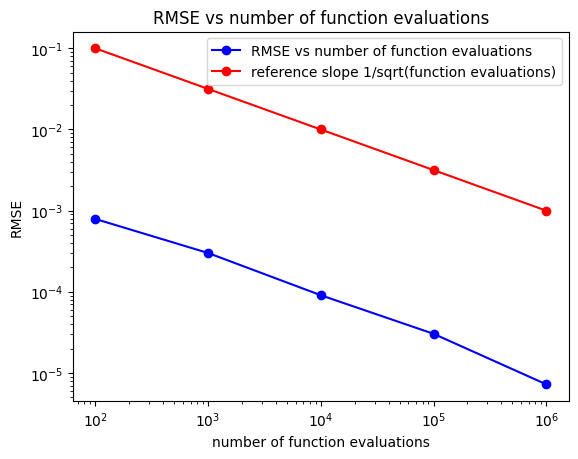

In [11]:
RMSEs = np.zeros(5)
iters = np.zeros(5)


for i in range(2, 7):
  iter = int((10**i)/2)
  iters[i-2] = iter*2
  approx_values = np.zeros(100)
  start = time.time()
  for j in range(100):
    approx_value = Monte_Carlo_antithetic_sampl(f, iter)
    approx_values[j] = approx_value
  end = time.time()

  empirical_bias = (1/100)*(np.sum(approx_values - math.pi/6))

  mean_of_approx = np.mean(approx_values)
  sample_var = (1/99)*(np.sum((approx_values - mean_of_approx)**2))

  empirical_var = sample_var * 99/100

  RMSE = np.sqrt((1/100)*(np.sum((approx_values - math.pi/6)**2)))
  RMSEs[i-2] = RMSE

  g_func = lambda x: (f(1-x) + f(x))/2

  conf_int = confidence_interval(g_func, iter, r)

  num = 0
  for j in range(100):
    if math.pi/6 - conf_int < approx_values[j] < math.pi/6 + conf_int:
      num += 1

  print(f"NUMBER OF FUNCTION EVALUATIONS = {2*iter} \n"
  f"NUMBER OF ANTITHETIC PAIRS = {iter} \n"
  f"time spent: {end - start} \n"
  f"empirical bias: {empirical_bias} \n"
  f"empirical variance: {empirical_var} \n"
  f"sample variance: {sample_var} \n"
  f"RMSE: {RMSE} \n"
  f"margin of error: {conf_int} \n"
  f"empirical coverage probability: {num} % \n"
  )

plt.loglog(iters, RMSEs, 'b-o', label = 'RMSE vs number of function evaluations')
g = lambda x: 1/math.sqrt(x)
sqrt_values = np.zeros(len(iters))
for i in range(len(iters)):
  sqrt_values[i] = g(iters[i])
plt.loglog(iters, sqrt_values, 'r-o', label = 'reference slope 1/sqrt(function evaluations)')
plt.title('RMSE vs number of function evaluations')
plt.xlabel('number of function evaluations')
plt.ylabel('RMSE')
plt.legend()
plt.show()

#3. Control Variates

The control variates method reduces variance by introducing a random variable $Z$ whose expected value is known and which is correlated with $f(U)$.

In this case, we choose

$$
Z=U-\frac{1}{2},
\qquad
\mathbb{E}[Z]=0.
$$

The estimator becomes

$$
\hat I_M^{CV}
=
\frac{1}{M}
\sum_{i=1}^{M}
\left[
f(U_i)-\beta Z_i
\right].
$$

Since $\mathbb{E}[Z]=0$, the expected value of the estimator is unchanged. The parameter $\beta$ is chosen to minimize its variance.

In [12]:
def Control_variates_func():
  f1 = lambda x: (x-1/2)*f(x)
  f2 = lambda x: (x-1/2)**2
  return approx_mean(f1)/approx_mean(f2)

beta = Control_variates_func()
print(f'The theoretical value of beta is {beta}')

def Monte_Carlo_control_variates(f, iter):
  sum = 0
  for i in range(iter):
    x = rd.uniform(0, 1)
    sum += f(x) - beta*(x-1/2)
  approx_value = sum/iter
  return approx_value


def improvement_measure_cont_var(f, beta):
  g = lambda x: f(x) - beta*(x-1/2)
  return approx_variance(f)/approx_variance(g)

imp_meas_cont_var = improvement_measure_cont_var(f, beta)
print(f'The theoretical improvement of the variance is {imp_meas_cont_var}')

The theoretical value of beta is 0.07379765558367925
The theoretical improvement of the variance is 11.420387429120726


Series of experiments

NUMBER OF ITERATIONS = 100 
time spent: 0.006575107574462891 
empirical bias: -0.00012869571679451685 
empirical variance: 4.3403938988380084e-07 
sample variance: 4.384236261452534e-07 
RMSE: 0.0006712689307610293 
margin of error: 0.0012934989499211532 
empirical coverage probability: 94 % 

NUMBER OF ITERATIONS = 1000 
time spent: 0.059252023696899414 
empirical bias: 4.210207079256012e-06 
empirical variance: 5.130558522730137e-08 
sample variance: 5.182382346192058e-08 
RMSE: 0.000226546487659711 
margin of error: 0.000409040283278692 
empirical coverage probability: 91 % 

NUMBER OF ITERATIONS = 10000 
time spent: 0.6001269817352295 
empirical bias: 3.4594428781664633e-06 
empirical variance: 4.960865741260711e-09 
sample variance: 5.010975496222941e-09 
RMSE: 7.051832021743009e-05 
margin of error: 0.00012934989499211532 
empirical coverage probability: 93 % 

NUMBER OF ITERATIONS = 100000 
time spent: 7.492938995361328 
empirical bias: 1.747290936691126e-06 
empirical variance:

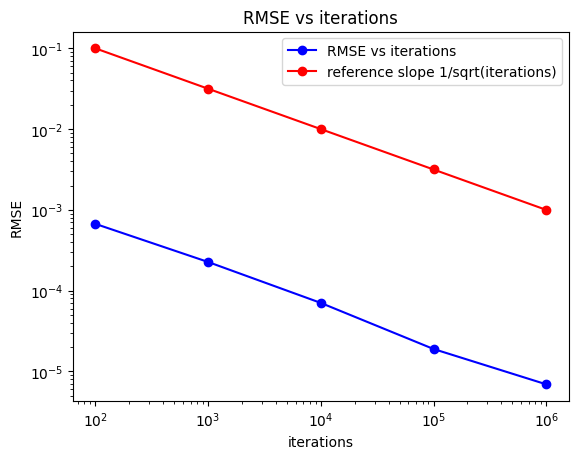

In [13]:
RMSEs = np.zeros(5)
iters = np.zeros(5)


for i in range(2, 7):
  iter = int((10**i))
  iters[i-2] = iter
  approx_values = np.zeros(100)
  start = time.time()
  for j in range(100):
    approx_value = Monte_Carlo_control_variates(f, iter)
    approx_values[j] = approx_value
  end = time.time()

  empirical_bias = (1/100)*(np.sum(approx_values - math.pi/6))

  mean_of_approx = np.mean(approx_values)
  sample_var = (1/99)*(np.sum((approx_values - mean_of_approx)**2))

  empirical_var = sample_var * 99/100

  RMSE = np.sqrt((1/100)*(np.sum((approx_values - math.pi/6)**2)))
  RMSEs[i-2] = RMSE

  g_func = lambda x: f(x) - beta*(x-1/2)

  conf_int = confidence_interval(g_func, iter, r)

  num = 0
  for j in range(100):
    if math.pi/6 - conf_int < approx_values[j] < math.pi/6 + conf_int:
      num += 1

  print(f"NUMBER OF ITERATIONS = {iter} \n"
  f"time spent: {end - start} \n"
  f"empirical bias: {empirical_bias} \n"
  f"empirical variance: {empirical_var} \n"
  f"sample variance: {sample_var} \n"
  f"RMSE: {RMSE} \n"
  f"margin of error: {conf_int} \n"
  f"empirical coverage probability: {num} % \n"
  )

plt.loglog(iters, RMSEs, 'b-o', label = 'RMSE vs iterations')
g = lambda x: 1/math.sqrt(x)
sqrt_values = np.zeros(len(iters))
for i in range(len(iters)):
  sqrt_values[i] = g(iters[i])
plt.loglog(iters, sqrt_values, 'r-o', label = 'reference slope 1/sqrt(iterations)')
plt.title('RMSE vs iterations')
plt.xlabel('iterations')
plt.ylabel('RMSE')
plt.legend()
plt.show()

#4. Importance Sampling

Importance Sampling reduces the variance by sampling from a different probability density $q$ instead of the uniform distribution. The density $q$ is chosen to assign more probability to regions where the integrand contributes more significantly to the integral.

If $X_1,\ldots,X_M$ are sampled from $q$, the estimator is

$$
\hat I_M^{IS}
=
\frac{1}{M}
\sum_{i=1}^{M}
\frac{f(X_i)}{q(X_i)},
\qquad X_i\sim q.
$$

The factor $1/q(X_i)$ corrects for the change of distribution, so that the estimator remains unbiased.


In [14]:
def bisection(f, a, b, tolla =1e-9, tollf = 1e-9):
  while abs(b-a) > tolla:
    c = (a+b)/2
    if abs(f(c)) < tollf:
      return c
    elif f(a)*f(c) < 0:
      b = c
    else:
      a = c
  return c



dens_func = lambda a_param: quad(lambda x: ((f(x)**2)*(1-2*x))/((a_param*(x-1/2)+1)**2), 0, 1)[0]

a = bisection(dens_func, 0, 1)


q = lambda x: a*(x-1/2)+1
# Q_1 is the inverse CDF of q(x) = a*x - a/2 + 1
# CDF Q(x) = a*x^2/2 - a*x/2 + x
Q_1 = lambda u: (-(1-a/2) + math.sqrt((1-a/2)**2 + 2*a*u)) / a

print(f'The theoretical value of a is {a}')
print(f'The theoretical value of b is {1-a/2}')

def sampling_from_q():
  x = rd.uniform(0, 1)
  return Q_1(x)


def Monte_Carlo_imp_sampling(f, iter):
  sum = 0
  for i in range(iter):
    x_sample = sampling_from_q()
    sum += f(x_sample) / q(x_sample)
  approx_value = sum/iter
  return approx_value

def variance_importance(f, q):
  appr_mn = approx_mean(f)
  return quad(lambda x: f(x)**2/q(x), 0, 1)[0] - appr_mn**2



def improvement_measure_imp_sampl(f):
  g = lambda x: f(x)/q(x)
  return approx_variance(f)/variance_importance(f, q)



imp_meas_imp_sampl = improvement_measure_imp_sampl(f)
print(f'The theoretical improvement of the variance is {imp_meas_imp_sampl}')

The theoretical value of a is 0.13941305875778198
The theoretical value of b is 0.930293470621109
The theoretical improvement of the variance is 11.486538465751963


Series of Experiments

NUMBER OF ITERATIONS = 100 
time spent: 0.012147188186645508 
empirical bias: -3.7908844643320675e-05 
empirical variance: 3.599270158166628e-07 
sample variance: 3.6356264223905335e-07 
RMSE: 0.0006011356721397044 
margin of error: 0.0012897689381824473 
empirical coverage probability: 97 % 

NUMBER OF ITERATIONS = 1000 
time spent: 0.11893200874328613 
empirical bias: 1.196445421336234e-05 
empirical variance: 4.767232238590224e-08 
sample variance: 4.815386099586085e-08 
RMSE: 0.0002186674885540278 
margin of error: 0.0004078607499993445 
empirical coverage probability: 94 % 

NUMBER OF ITERATIONS = 10000 
time spent: 1.1923387050628662 
empirical bias: -4.40130118790405e-06 
empirical variance: 4.108377476754136e-09 
sample variance: 4.149876239145592e-09 
RMSE: 6.424755971164027e-05 
margin of error: 0.00012897689381824475 
empirical coverage probability: 95 % 

NUMBER OF ITERATIONS = 100000 
time spent: 13.53165602684021 
empirical bias: 4.507440532734996e-06 
empirical variance:

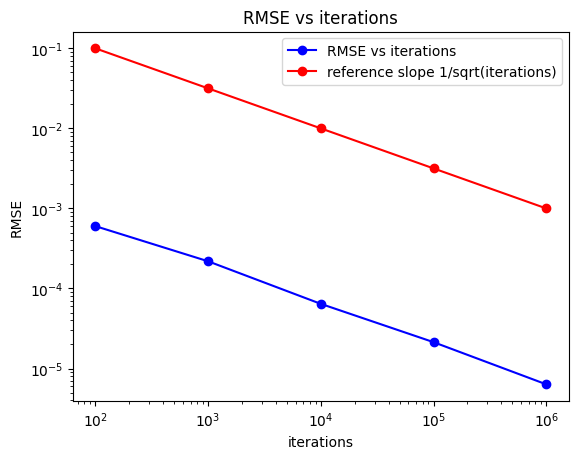

In [15]:
RMSEs = np.zeros(5)
iters = np.zeros(5)


for i in range(2, 7):
  iter = int((10**i))
  iters[i-2] = iter
  approx_values = np.zeros(100)
  start = time.time()
  for j in range(100):
    approx_value = Monte_Carlo_imp_sampling(f, iter)
    approx_values[j] = approx_value
  end = time.time()

  empirical_bias = (1/100)*(np.sum(approx_values - math.pi/6))

  mean_of_approx = np.mean(approx_values)
  sample_var = (1/99)*(np.sum((approx_values - mean_of_approx)**2))

  empirical_var = sample_var * 99/100

  RMSE = np.sqrt((1/100)*(np.sum((approx_values - math.pi/6)**2)))
  RMSEs[i-2] = RMSE


  conf_int = r * math.sqrt(variance_importance(f, q) / iter)

  num = 0
  for j in range(100):
    if math.pi/6 - conf_int < approx_values[j] < math.pi/6 + conf_int:
      num += 1

  print(f"NUMBER OF ITERATIONS = {iter} \n"
  f"time spent: {end - start} \n"
  f"empirical bias: {empirical_bias} \n"
  f"empirical variance: {empirical_var} \n"
  f"sample variance: {sample_var} \n"
  f"RMSE: {RMSE} \n"
  f"margin of error: {conf_int} \n"
  f"empirical coverage probability: {num} % \n"
  )

plt.loglog(iters, RMSEs, 'b-o', label = 'RMSE vs iterations')
h = lambda x: 1/math.sqrt(x)
sqrt_values = np.zeros(len(iters))
for i in range(len(iters)):
  sqrt_values[i] = h(iters[i])
plt.loglog(iters, sqrt_values, 'r-o', label = 'reference slope 1/sqrt(iterations)')
plt.title('RMSE vs iterations')
plt.xlabel('iterations')
plt.ylabel('RMSE')
plt.legend()
plt.show()